# District-Wise Rainfall Analysis

## Introduction
This project analyzes district-wise rainfall normal data of India
using Python and Data Analysis libraries.

## Objectives
- Understand the dataset.
- Analyze missing values and duplicate records.
- Study rainfall statistics.
- Identify rainfall outliers.
- Analyze seasonal rainfall contribution.
- Compare monsoon rainfall with annual rainfall.
- Identify top 10 states by average annual rainfall.
- Visualize rainfall data using charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"D:\python_projects\district_wise_rainfall_analysis\dataset\district wise rainfall normal.xlsx"

df = pd.read_excel(file_path)

df.head()

,STATE_UT_NAME,DISTRICT,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN And NICOBAR ISLANDS,NICOBAR,107.3,57.9,65.2,117.0,358.5,295.5,285.0,271.9,354.8,326.0,315.2,250.9,2805.2,165.2,540.7,1207.2,892.1
1,ANDAMAN And NICOBAR ISLANDS,SOUTH ANDAMAN,43.7,26.0,18.6,90.5,374.4,457.2,421.3,423.1,455.6,301.2,275.8,128.3,3015.7,69.7,483.5,1757.2,705.3
2,ANDAMAN And NICOBAR ISLANDS,N & M ANDAMAN,32.7,15.9,8.6,53.4,343.6,503.3,465.4,460.9,454.8,276.1,198.6,100.0,2913.3,48.6,405.6,1884.4,574.7
3,ARUNACHAL PRADESH,LOHIT,42.2,80.8,176.4,358.5,306.4,447.0,660.1,427.8,313.6,167.1,34.1,29.8,3043.8,123.0,841.3,1848.5,231.0
4,ARUNACHAL PRADESH,EAST SIANG,33.3,79.5,105.9,216.5,323.0,738.3,990.9,711.2,568.0,206.9,29.5,31.7,4034.7,112.8,645.4,3008.4,268.1


In [3]:
num_records, num_columns = df.shape

print("Number of Records:", num_records)
print("Number of Columns:", num_columns)

Number of Records: 641
Number of Columns: 19


In [4]:
categorical_cols = ['STATE_UT_NAME', 'DISTRICT']

numerical_cols = [
    c for c in df.columns
    if c not in categorical_cols
]

missing_values = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()

print("--------------------------------")
print("------- DATASET SUMMARY --------")
print("--------------------------------")

print(f"Number of Records      : {num_records}")
print(f"Number of Columns      : {num_columns}")
print(f"Numerical Attributes   : {len(numerical_cols)}")
print(f"Categorical Attributes : {len(categorical_cols)}")

print("\n--- DATA QUALITY ---")
print(f"Total Missing Values : {missing_values}")
print(f"Total Duplicate Rows : {duplicate_rows}")

--------------------------------
------- DATASET SUMMARY --------
--------------------------------
Number of Records      : 641
Number of Columns      : 19
Numerical Attributes   : 17
Categorical Attributes : 2

--- DATA QUALITY ---
Total Missing Values : 0
Total Duplicate Rows : 0


In [5]:
print("=" * 55)
print("            IMPORTANT ATTRIBUTES")
print("=" * 55)

print()

print(f"{'Attribute':<16}{'Data Type':<14}{'Description'}")
print("-" * 55)

print(f"{'STATE_UT_NAME':<16}{'Categorical':<14}State / UT name")
print(f"{'DISTRICT':<16}{'Categorical':<14}District name")
print(f"{'JAN - DEC':<16}{'Numerical':<14}Monthly rainfall (mm)")
print(f"{'ANNUAL':<16}{'Numerical':<14}Total annual rainfall (mm)")
print(f"{'Jan-Feb':<16}{'Numerical':<14}Winter season rainfall (mm)")
print(f"{'Mar-May':<16}{'Numerical':<14}Pre-monsoon rainfall (mm)")
print(f"{'Jun-Sep':<16}{'Numerical':<14}Monsoon rainfall (mm)")
print(f"{'Oct-Dec':<16}{'Numerical':<14}Post-monsoon rainfall (mm)")
print()

            IMPORTANT ATTRIBUTES

Attribute       Data Type     Description
-------------------------------------------------------
STATE_UT_NAME   Categorical   State / UT name
DISTRICT        Categorical   District name
JAN - DEC       Numerical     Monthly rainfall (mm)
ANNUAL          Numerical     Total annual rainfall (mm)
Jan-Feb         Numerical     Winter season rainfall (mm)
Mar-May         Numerical     Pre-monsoon rainfall (mm)
Jun-Sep         Numerical     Monsoon rainfall (mm)
Oct-Dec         Numerical     Post-monsoon rainfall (mm)



# PAGE 2 - DATA UNDERSTANDING

This section explores the dataset by displaying the first records,
data types, missing values, duplicate records, and attributes.

In [6]:
print("FIRST 5 RECORDS")
print("-" * 90)

print(df.head())

FIRST 5 RECORDS
------------------------------------------------------------------------------------------
                 STATE_UT_NAME       DISTRICT    JAN   FEB    MAR    APR  \
0  ANDAMAN And NICOBAR ISLANDS        NICOBAR  107.3  57.9   65.2  117.0   
1  ANDAMAN And NICOBAR ISLANDS  SOUTH ANDAMAN   43.7  26.0   18.6   90.5   
2  ANDAMAN And NICOBAR ISLANDS  N & M ANDAMAN   32.7  15.9    8.6   53.4   
3            ARUNACHAL PRADESH          LOHIT   42.2  80.8  176.4  358.5   
4            ARUNACHAL PRADESH     EAST SIANG   33.3  79.5  105.9  216.5   

     MAY    JUN    JUL    AUG    SEP    OCT    NOV    DEC  ANNUAL  Jan-Feb  \
0  358.5  295.5  285.0  271.9  354.8  326.0  315.2  250.9  2805.2    165.2   
1  374.4  457.2  421.3  423.1  455.6  301.2  275.8  128.3  3015.7     69.7   
2  343.6  503.3  465.4  460.9  454.8  276.1  198.6  100.0  2913.3     48.6   
3  306.4  447.0  660.1  427.8  313.6  167.1   34.1   29.8  3043.8    123.0   
4  323.0  738.3  990.9  711.2  568.0  206.9   

In [7]:
print("DATA TYPES")
print("-" * 60)

print(df.dtypes)

DATA TYPES
------------------------------------------------------------
STATE_UT_NAME     object
DISTRICT          object
JAN              float64
FEB              float64
MAR              float64
APR              float64
MAY              float64
JUN              float64
JUL              float64
AUG              float64
SEP              float64
OCT              float64
NOV              float64
DEC              float64
ANNUAL           float64
Jan-Feb          float64
Mar-May          float64
Jun-Sep          float64
Oct-Dec          float64
dtype: object


In [8]:
print("MISSING VALUES")
print("-" * 60)

print(df.isnull().sum())

print()

print("Total Missing Values:", df.isnull().sum().sum())

MISSING VALUES
------------------------------------------------------------
STATE_UT_NAME    0
DISTRICT         0
JAN              0
FEB              0
MAR              0
APR              0
MAY              0
JUN              0
JUL              0
AUG              0
SEP              0
OCT              0
NOV              0
DEC              0
ANNUAL           0
Jan-Feb          0
Mar-May          0
Jun-Sep          0
Oct-Dec          0
dtype: int64

Total Missing Values: 0


In [9]:
print("DUPLICATE RECORDS")
print("-" * 60)

print("Number of Duplicate Records:", df.duplicated().sum())

DUPLICATE RECORDS
------------------------------------------------------------
Number of Duplicate Records: 0


In [10]:
categorical_cols = ["STATE_UT_NAME", "DISTRICT"]

numerical_cols = [
    c for c in df.columns
    if c not in categorical_cols
]

print("ATTRIBUTE SUMMARY")
print("-" * 60)

print("Numerical Attributes:", len(numerical_cols))
print("Categorical Attributes:", len(categorical_cols))

print()

print("Numerical Columns:")

for c in numerical_cols:
    print("-", c)

print()

print("Categorical Columns:")

for c in categorical_cols:
    print("-", c)

print()

ATTRIBUTE SUMMARY
------------------------------------------------------------
Numerical Attributes: 17
Categorical Attributes: 2

Numerical Columns:
- JAN
- FEB
- MAR
- APR
- MAY
- JUN
- JUL
- AUG
- SEP
- OCT
- NOV
- DEC
- ANNUAL
- Jan-Feb
- Mar-May
- Jun-Sep
- Oct-Dec

Categorical Columns:
- STATE_UT_NAME
- DISTRICT



In [11]:
descriptions = {
    "STATE_UT_NAME": "Name of the Indian State or Union Territory",
    "DISTRICT": "Name of the district within the state",
    "JAN": "Normal rainfall recorded in January (mm)",
    "FEB": "Normal rainfall recorded in February (mm)",
    "MAR": "Normal rainfall recorded in March (mm)",
    "APR": "Normal rainfall recorded in April (mm)",
    "MAY": "Normal rainfall recorded in May (mm)",
    "JUN": "Normal rainfall recorded in June (mm)",
    "JUL": "Normal rainfall recorded in July (mm)",
    "AUG": "Normal rainfall recorded in August (mm)",
    "SEP": "Normal rainfall recorded in September (mm)",
    "OCT": "Normal rainfall recorded in October (mm)",
    "NOV": "Normal rainfall recorded in November (mm)",
    "DEC": "Normal rainfall recorded in December (mm)",
    "ANNUAL": "Total normal annual rainfall (mm)",
    "Jan-Feb": "Total winter season rainfall (mm)",
    "Mar-May": "Total pre-monsoon rainfall (mm)",
    "Jun-Sep": "Total monsoon rainfall (mm)",
    "Oct-Dec": "Total post-monsoon rainfall (mm)"
}

print("IMPORTANT ATTRIBUTES")
print("-" * 90)

print("Attribute | Data Type | Description")
print("-" * 90)

for col in df.columns:
    dtype = "str" if df[col].dtype == "object" else str(df[col].dtype)

    print(
        f"{col} | {dtype} | "
        f"{descriptions.get(col, '')}"
    )

IMPORTANT ATTRIBUTES
------------------------------------------------------------------------------------------
Attribute | Data Type | Description
------------------------------------------------------------------------------------------
STATE_UT_NAME | str | Name of the Indian State or Union Territory
DISTRICT | str | Name of the district within the state
JAN | float64 | Normal rainfall recorded in January (mm)
FEB | float64 | Normal rainfall recorded in February (mm)
MAR | float64 | Normal rainfall recorded in March (mm)
APR | float64 | Normal rainfall recorded in April (mm)
MAY | float64 | Normal rainfall recorded in May (mm)
JUN | float64 | Normal rainfall recorded in June (mm)
JUL | float64 | Normal rainfall recorded in July (mm)
AUG | float64 | Normal rainfall recorded in August (mm)
SEP | float64 | Normal rainfall recorded in September (mm)
OCT | float64 | Normal rainfall recorded in October (mm)
NOV | float64 | Normal rainfall recorded in November (mm)
DEC | float64 | Normal r

In [12]:
print("MISSING VALUES")
print("-" * 60)

print("Total Missing Values:", df.isnull().sum().sum())

print()

MISSING VALUES
------------------------------------------------------------
Total Missing Values: 0



In [13]:
print("DUPLICATE RECORDS")
print("-" * 60)

print("Number of Duplicate Records:", df.duplicated().sum())

DUPLICATE RECORDS
------------------------------------------------------------
Number of Duplicate Records: 0


Top 10 States by Average Annual Rainfall
STATE_UT_NAME
MEGHALAYA                      3682.842857
GOA                            3278.500000
KERALA                         2937.392857
ARUNACHAL PRADESH              2927.375000
ANDAMAN And NICOBAR ISLANDS    2911.400000
SIKKIM                         2838.350000
MIZORAM                        2616.322222
MANIPUR                        2496.633333
TRIPURA                        2479.125000
ASSAM                          2454.359259
Name: ANNUAL, dtype: float64


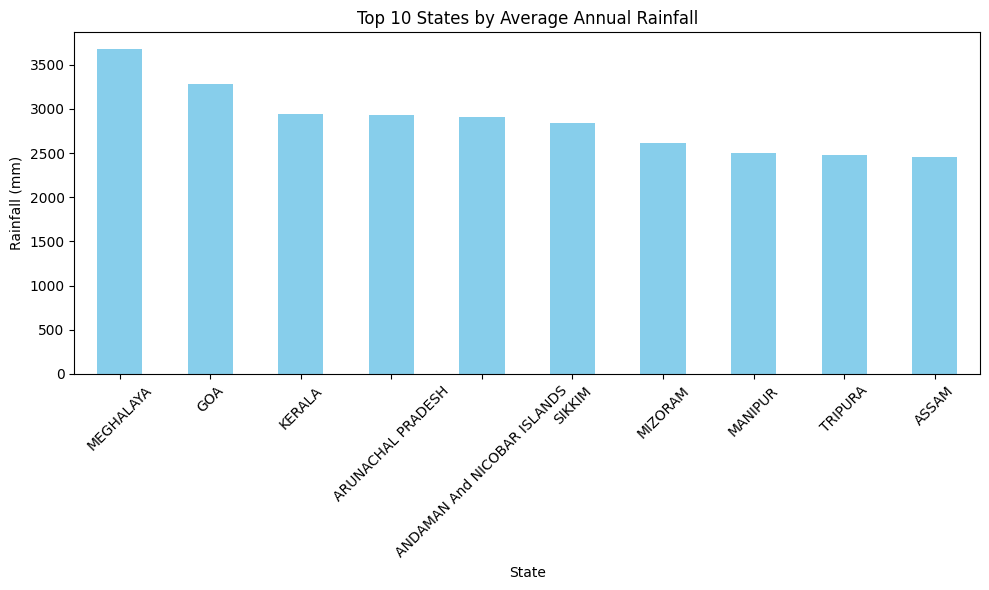

In [14]:
top_states = (
    df.groupby('STATE_UT_NAME')['ANNUAL']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 States by Average Annual Rainfall")
print(top_states)

top_states.plot(
    kind='bar',
    color='skyblue',
    figsize=(10, 6)
)

plt.title("Top 10 States by Average Annual Rainfall")
plt.ylabel("Rainfall (mm)")
plt.xlabel("State")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("bar_chart.png")
plt.show()

Average Rainfall by Season:
Jan-Feb      39.339470
Mar-May     157.113105
Jun-Sep    1007.802340
Oct-Dec     142.714665
dtype: float64


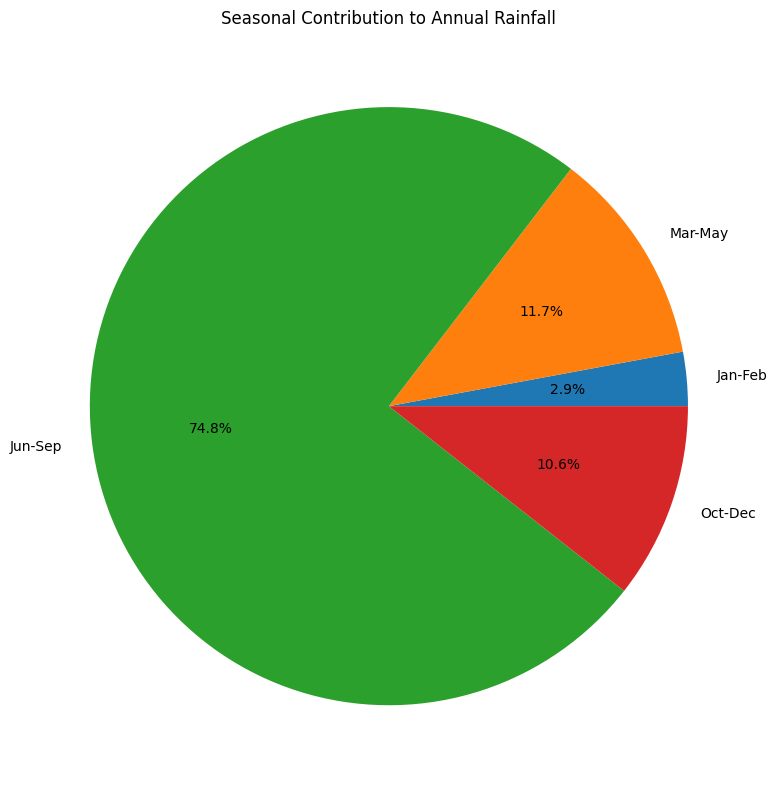

In [15]:
seasons = df[
    ['Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']
].mean()

print("Average Rainfall by Season:")
print(seasons)

seasons.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8, 8)
)

plt.title("Seasonal Contribution to Annual Rainfall")
plt.ylabel("")
plt.tight_layout()

plt.show()

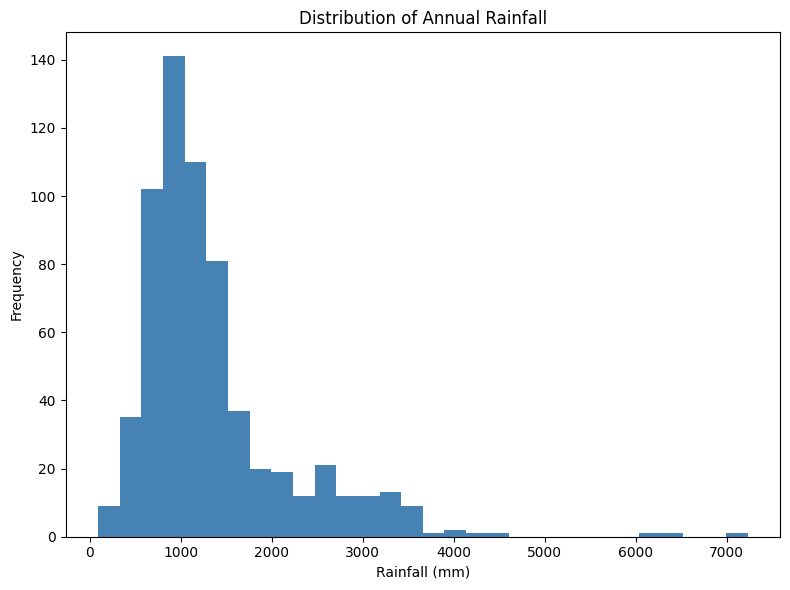

In [16]:
df['ANNUAL'].plot(
    kind='hist',
    bins=30,
    color='steelblue',
    figsize=(8, 6)
)

plt.title("Distribution of Annual Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("histogram.png")
plt.show()

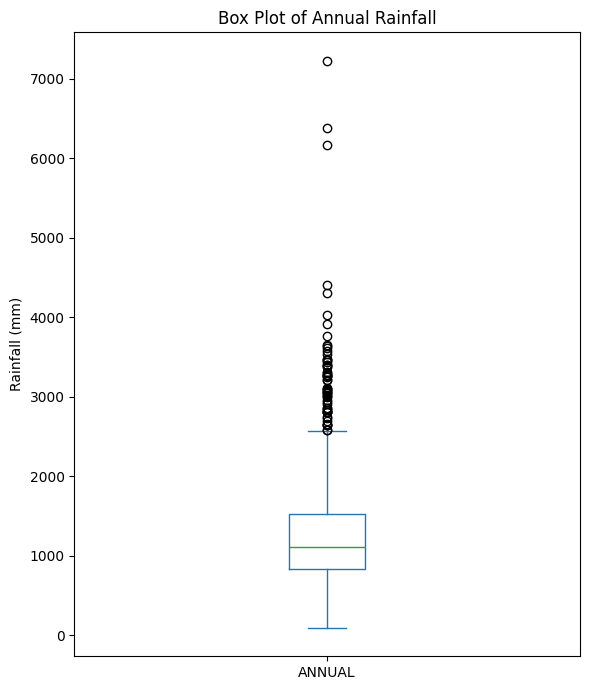

In [17]:
df['ANNUAL'].plot(
    kind='box',
    figsize=(6, 7)
)

plt.title("Box Plot of Annual Rainfall")
plt.ylabel("Rainfall (mm)")

plt.tight_layout()
plt.savefig("boxplot.png")
plt.show()

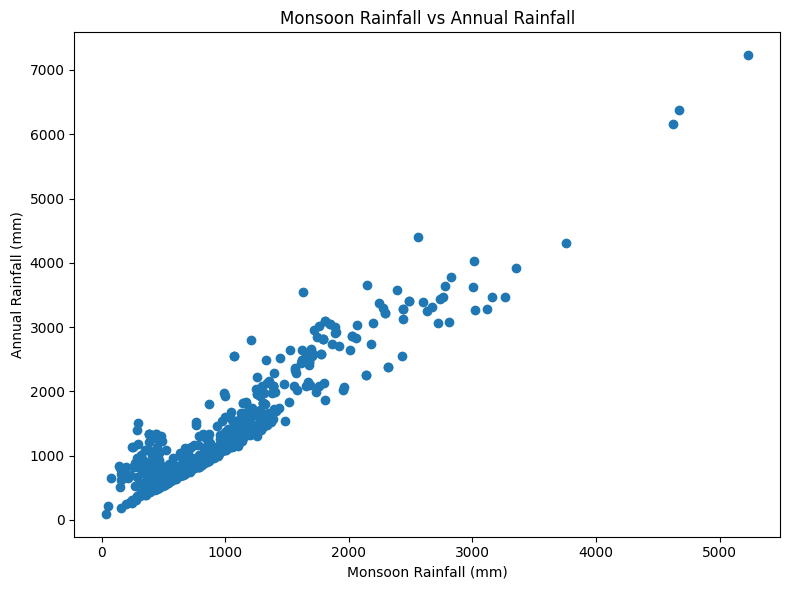

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Jun-Sep'],
    df['ANNUAL']
)

plt.title("Monsoon Rainfall vs Annual Rainfall")
plt.xlabel("Monsoon Rainfall (mm)")
plt.ylabel("Annual Rainfall (mm)")

plt.tight_layout()
plt.savefig("scatter_plot.png")
plt.show()

# PAGE 4 - STATISTICAL ANALYSIS

This section calculates statistical measures of annual rainfall
such as mean, median, mode, minimum, maximum, range,
and standard deviation.

In [19]:
print("-" * 55)
print("STATISTICAL ANALYSIS ON ANNUAL RAINFALL")
print("-" * 55)

print("Mean:", df['ANNUAL'].mean())
print("Median:", df['ANNUAL'].median())
print("Mode:", df['ANNUAL'].mode()[0])
print("Minimum:", df['ANNUAL'].min())
print("Maximum:", df['ANNUAL'].max())

print(
    "Range:",
    df['ANNUAL'].max() - df['ANNUAL'].min()
)

print("Standard Deviation:", df['ANNUAL'].std())

-------------------------------------------------------
STATISTICAL ANALYSIS ON ANNUAL RAINFALL
-------------------------------------------------------
Mean: 1346.9695787831513
Median: 1116.2
Mode: 747.1
Minimum: 94.6
Maximum: 7229.3
Range: 7134.7
Standard Deviation: 838.878873833242


# PAGE 5 - OUTLIER DETECTION

The Interquartile Range (IQR) method is used to detect
outliers in annual rainfall.

IQR = Q3 - Q1

Lower Limit = Q1 - 1.5 * IQR

Upper Limit = Q3 + 1.5 * IQR

In [20]:
print("-" * 55)
print("OUTLIER DETECTION USING IQR METHOD")
print("-" * 55)

Q1 = df['ANNUAL'].quantile(0.25)
Q3 = df['ANNUAL'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['ANNUAL'] < lower_limit) |
    (df['ANNUAL'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Number of outliers:", len(outliers))

print()

print(
    outliers[
        ['STATE_UT_NAME', 'DISTRICT', 'ANNUAL']
    ]
)

-------------------------------------------------------
OUTLIER DETECTION USING IQR METHOD
-------------------------------------------------------
Q1: 830.4
Q3: 1530.9
IQR: 700.5000000000001
Lower Limit: -220.35000000000025
Upper Limit: 2581.6500000000005
Number of outliers: 61

                   STATE_UT_NAME        DISTRICT  ANNUAL
0    ANDAMAN And NICOBAR ISLANDS         NICOBAR  2805.2
1    ANDAMAN And NICOBAR ISLANDS   SOUTH ANDAMAN  3015.7
2    ANDAMAN And NICOBAR ISLANDS   N & M ANDAMAN  2913.3
3              ARUNACHAL PRADESH           LOHIT  3043.8
4              ARUNACHAL PRADESH      EAST SIANG  4034.7
..                           ...             ...     ...
634                       KERALA        THRISSUR  3063.1
636                       KERALA          IDUKKI  3302.5
637                       KERALA        KASARGOD  3621.6
638                       KERALA  PATHANAMTHITTA  2958.4
639                       KERALA         WAYANAD  3253.1

[61 rows x 3 columns]


# PAGE 6 - CORRELATION ANALYSIS

Correlation measures the relationship between two variables.

We calculate the correlation between monsoon rainfall (Jun-Sep)
and annual rainfall.

In [21]:
print("-" * 55)
print("CORRELATION BETWEEN MONSOON AND ANNUAL RAINFALL")
print("-" * 55)

correlation = df['Jun-Sep'].corr(df['ANNUAL'])

print(
    "Correlation between Monsoon and Annual rainfall:",
    correlation
)

-------------------------------------------------------
CORRELATION BETWEEN MONSOON AND ANNUAL RAINFALL
-------------------------------------------------------
Correlation between Monsoon and Annual rainfall: 0.9362376488548929


# PAGE 7 - TOP 10 STATES BY AVERAGE ANNUAL RAINFALL

This section identifies the 10 states having the highest
average annual rainfall.

In [22]:
print("-" * 55)
print("TOP 10 STATES BY AVERAGE ANNUAL RAINFALL")
print("-" * 55)

top_states = (
    df.groupby('STATE_UT_NAME')['ANNUAL']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(top_states)

-------------------------------------------------------
TOP 10 STATES BY AVERAGE ANNUAL RAINFALL
-------------------------------------------------------
STATE_UT_NAME
MEGHALAYA                      3682.842857
GOA                            3278.500000
KERALA                         2937.392857
ARUNACHAL PRADESH              2927.375000
ANDAMAN And NICOBAR ISLANDS    2911.400000
SIKKIM                         2838.350000
MIZORAM                        2616.322222
MANIPUR                        2496.633333
TRIPURA                        2479.125000
ASSAM                          2454.359259
Name: ANNUAL, dtype: float64


# CONCLUSION

In this project, district-wise rainfall normal data was analyzed
using Python.

The dataset was explored to understand its structure,
attributes, missing values, and duplicate records.

Statistical analysis was performed on annual rainfall using
mean, median, mode, minimum, maximum, range, and standard deviation.

The IQR method was used to detect outliers.

Visualizations such as bar charts, pie charts, histograms,
box plots, and scatter plots were created to understand
rainfall patterns.

The analysis also identified the top 10 states by average
annual rainfall and examined the correlation between monsoon
rainfall and annual rainfall.

Libraries used:
- Pandas
- NumPy
- Matplotlib

This project demonstrates the use of Python for data analysis,
statistical calculations, and data visualization.